In [ ]:
import tensorflow as tf
import keras
import os

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Legacy:", os.environ.get("TF_USE_LEGACY_KERAS"))

TensorFlow: 2.20.0
Keras: 3.13.2
Legacy: None


In [1]:
# ==============================
# Mount Drive
# ==============================
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
import numpy as np
from keras.layers import (Conv1D, MaxPooling1D, Dense, Dropout,
                          Flatten, Input, LayerNormalization,
                          MultiHeadAttention, GlobalAveragePooling1D,
                          GlobalMaxPooling1D, Add)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import tensorflow as tf

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

from numpy import savetxt
@tf.keras.utils.register_keras_serializable()
class PositionalEncoding(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, x):
        seq_len = tf.shape(x)[1]
        d_model = tf.shape(x)[2]

        pos = tf.cast(tf.range(seq_len), tf.float32)[:, tf.newaxis]
        i = tf.cast(tf.range(d_model), tf.float32)[tf.newaxis, :]

        angle_rates = 1 / tf.pow(
            10000.0,
            (2 * (i // 2)) / tf.cast(d_model, tf.float32)
        )

        angle_rads = pos * angle_rates

        sines = tf.sin(angle_rads[:, 0::2])
        cosines = tf.cos(angle_rads[:, 1::2])

        pos_encoding = tf.concat([sines, cosines], axis=-1)
        pos_encoding = pos_encoding[tf.newaxis, ...]

        return x + pos_encoding

    def get_config(self):
        return super().get_config()


In [3]:
import tensorflow as tf
from tensorflow.keras.layers import BatchNormalization, MultiHeadAttention, Dropout, LayerNormalization, Dense

# TransformerBlock class
class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout_rate

        self.att = MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.dropout1 = Dropout(dropout_rate)
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.ffn_layer1 = Dense(ff_dim, activation="relu")
        self.ffn_layer2 = Dense(d_model)
        self.dropout2 = Dropout(dropout_rate)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)

    def call(self, inputs, training=False):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)

        ffn_output = self.ffn_layer1(out1)
        ffn_output = self.ffn_layer2(ffn_output)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

    def get_config(self):
        config = super().get_config()
        config.update({
            "d_model": self.d_model,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "dropout_rate": self.dropout_rate,
        })
        return config


In [4]:
import keras
keras.config.disable_traceback_filtering()

In [5]:
import tensorflow as tf

@tf.keras.utils.register_keras_serializable()
class PatchedLSTM(tf.keras.layers.LSTM):
    def __init__(self, *args, **kwargs):
        # Remove obsolete argument if present
        kwargs.pop("time_major", None)
        super().__init__(*args, **kwargs)

In [6]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, accuracy_score, mean_squared_error
from matplotlib.pyplot import figure
import scipy as sp
import numpy as np
from tensorflow.keras.models import load_model

# Load Test Data
# ==============================
file_prefix = '/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xc'
file_suffix = '_testX.npy'
file_suffix_p = '_testP.npy'

Xc = {}
Xcp = {}

for snr in range(10,21):
    Xc[f'Xc{snr}_testX'] = np.load(file_prefix + str(snr) + file_suffix)
    Xcp[f'Xc{snr}_testP'] = np.load(file_prefix + str(snr) + file_suffix_p)

print("Files loaded successfully ✅")

Yc_test = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_testX.npy')
Yc_testP = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_testP.npy')

# ==============================
# Load Models
# ==============================
CLSTM_model = load_model(
    '/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/CNN_LSTM.h5',


     custom_objects={
        "LSTM": PatchedLSTM,
        "PatchedLSTM": PatchedLSTM,
    },
    compile=False,
    safe_mode=False


)


LSTM_model = load_model(
    '/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/CNN_LSTM_MLP1.h5',
    compile=False,

)

from tensorflow.keras.models import load_model

Coop_model = load_model(
    "/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Cooperative_LSTM.h5",
    custom_objects={
        "LSTM": PatchedLSTM,
        "PatchedLSTM": PatchedLSTM,
    },
    compile=False,
    safe_mode=False
)

Cnn_blstm = load_model(
    '/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/CNN_BLSTM.h5',
     custom_objects={

    },
    compile = False,

    )

CNN_Transformer = load_model(
    "/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/CNN-Transformer2.keras",
    custom_objects={"PositionalEncoding": PositionalEncoding},
    compile=False,
    safe_mode=False,
)

Files loaded successfully ✅


In [7]:
print("CNN-LSTM           :", CLSTM_model.count_params())
print("CNN-LSTM-MLP       :", LSTM_model.count_params())
print("Cooperative LSTM   :", Coop_model.count_params())
print("CNN-BLSTM          :", Cnn_blstm.count_params())
print("CNN-Transformer    :", CNN_Transformer.count_params())

CNN-LSTM           : 3017890
CNN-LSTM-MLP       : 5410082
Cooperative LSTM   : 4021674
CNN-BLSTM          : 2985122
CNN-Transformer    : 84930


891/891 ━━━━━━━━━━━━━━━━━━━━ 32s 35ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 31s 34ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 36s 40ms/step
811/811 ━━━━━━━━━━━━━━━━━━━━ 38s 46ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step


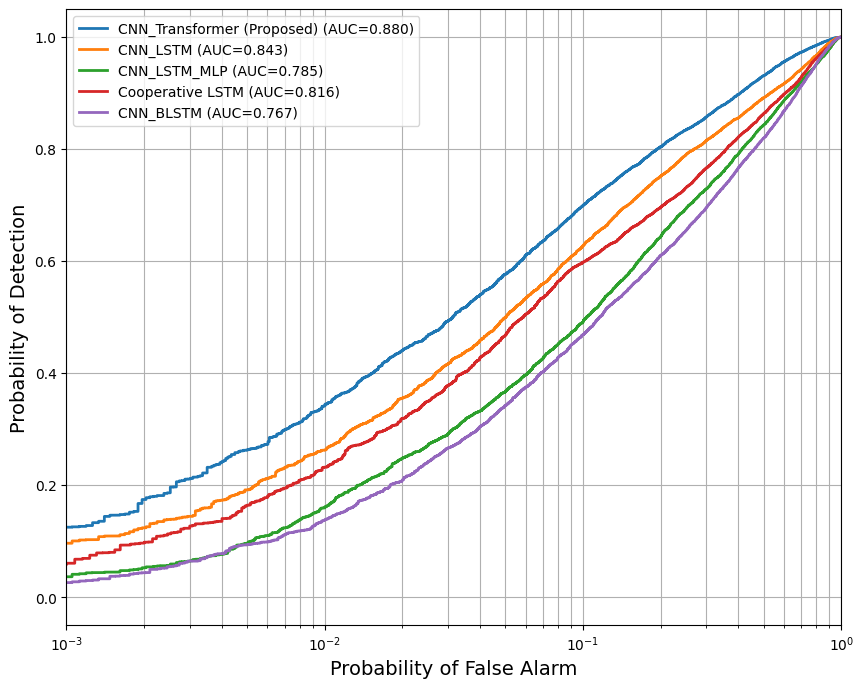

In [8]:

# ==============================
# Evaluate for SNR = 14
# ==============================
snr_value = 14

Xc14_test = Xc[f'Xc{snr_value}_testX']
Xc14_testP = Xcp[f'Xc{snr_value}_testP']

S = 4
Sp = 3

# Split data for CNN/LSTM models
idx = np.arange(S+1) * int(Xc14_test.shape[0] / S)

Xu_test = Xc14_test[idx[0]:idx[1]]
Xx_test = Xc14_test[idx[1]:idx[2]]
Xy_test = Xc14_test[idx[2]:idx[3]]
Xz_test = Xc14_test[idx[3]:idx[4]]

# Slice corresponding labels
Y14_test = Yc_test[idx[0]:idx[4]]

# Split data for Cooperative model
pidx = np.arange(Sp+1) * int(Xc14_testP.shape[0] / Sp)

Xx_testP = Xc14_testP[pidx[0]:pidx[1]]
Xy_testP = Xc14_testP[pidx[1]:pidx[2]]
Xz_testP = Xc14_testP[pidx[2]:pidx[3]]

# Slice cooperative labels
Y14_testP = Yc_testP[pidx[0]:pidx[3]]

# ==============================
# Predictions
# ==============================
# Concatenate inputs for CNN_Transformer model which expects a single input
X_transformer_input = np.concatenate([Xu_test, Xx_test, Xy_test, Xz_test], axis=-1)
y_CNN_Transformer = CNN_Transformer.predict(X_transformer_input)

y_CLSTM = CLSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_LSTM = LSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_Coop = Coop_model.predict([Xx_testP, Xy_testP, Xz_testP])
y_Cnn_blstm = Cnn_blstm.predict([Xu_test, Xx_test, Xy_test, Xz_test])



# ==============================
# ROC Calculation
# ==============================
fp5, tp5, _ = roc_curve(Y14_test[:,1], y_CNN_Transformer[:,1])
fp, tp, _ = roc_curve(Y14_test[:,1], y_CLSTM[:,1])
fp1, tp1, _ = roc_curve(Y14_test[:,1], y_LSTM[:,1])
fp3, tp3, _ = roc_curve(Y14_testP[:,1], y_Coop[:,1])
fp4, tp4, _ = roc_curve(Y14_test[:,1], y_Cnn_blstm[:,1])

roc_auc5 = auc(fp5, tp5)
roc_auc = auc(fp, tp)
roc_auc1 = auc(fp1, tp1)
roc_auc3 = auc(fp3, tp3)
roc_auc4 = auc(fp4, tp4)


# ==============================
# Plot ROC
# ==============================
plt.figure(figsize=(10,8))
plt.xscale('log')

plt.plot(fp5, tp5, lw=2, label=f'CNN_Transformer (Proposed) (AUC={roc_auc5:.3f})')
plt.plot(fp, tp, lw=2, label=f'CNN_LSTM (AUC={roc_auc:.3f})')
plt.plot(fp1, tp1, lw=2, label=f'CNN_LSTM_MLP (AUC={roc_auc1:.3f})')
plt.plot(fp3, tp3, lw=2, label=f'Cooperative LSTM (AUC={roc_auc3:.3f})')
plt.plot(fp4, tp4, lw=2, label=f'CNN_BLSTM (AUC={roc_auc4:.3f})')


plt.xlim([0.001,1])
plt.xlabel('Probability of False Alarm', fontsize=14)
plt.ylabel('Probability of Detection', fontsize=14)
plt.legend()
plt.grid(True, which="both")
plt.show()


In [9]:
# ==============================
# Function: Pd at fixed Pfa
# ==============================
def compute_pd_at_pfa(y_true, y_pred, target_pfa=0.1):
    fp, tp, _ = roc_curve(y_true, y_pred)

    # If exact Pfa exists
    if target_pfa in fp:
        return tp[np.where(fp == target_pfa)][0]

    # Safe interpolation
    idx_low = np.where(fp < target_pfa)[0]
    idx_high = np.where(fp > target_pfa)[0]

    if len(idx_low) == 0 or len(idx_high) == 0:
        return tp[-1]  # fallback

    idx_low = idx_low[-1]
    idx_high = idx_high[0]

    x1, x2 = fp[idx_low], fp[idx_high]
    y1, y2 = tp[idx_low], tp[idx_high]

    return y1 + (y2 - y1) * (target_pfa - x1) / (x2 - x1)


# ==============================
# Define SNR Range (OUTSIDE function!)
# ==============================
SNR_range = range(10,21)

Pd_CLSTM = []
Pdh_LSTM = []
Pd_Coop = []
pd_Cnn_blstm = []
pd_transformer = []

for snr in SNR_range:

    X_test = Xc[f'Xc{snr}_testX']
    X_testP = Xcp[f'Xc{snr}_testP']

    S = 4
    Sp = 3

    idx = np.arange(S+1) * int(X_test.shape[0] / S)
    pidx = np.arange(Sp+1) * int(X_testP.shape[0] / Sp)

    # CNN/LSTM split
    Xu = X_test[idx[0]:idx[1]]
    Xx = X_test[idx[1]:idx[2]]
    Xy = X_test[idx[2]:idx[3]]
    Xz = X_test[idx[3]:idx[4]]

    Y_slice = Yc_test[idx[0]:idx[4]]

    # Cooperative split
    XxP = X_testP[pidx[0]:pidx[1]]
    XyP = X_testP[pidx[1]:pidx[2]]
    XzP = X_testP[pidx[2]:pidx[3]]

    Y_sliceP = Yc_testP[pidx[0]:pidx[3]]

    # Predictions
    y1 = CLSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
    y2 = LSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
    y3 = Coop_model.predict([XxP, XyP, XzP], verbose=0)
    y4 = Cnn_blstm.predict([Xu, Xx, Xy, Xz], verbose=0)
    # Concatenate inputs for CNN_Transformer model which expects a single input
    X_transformer_input_loop = np.concatenate([Xu, Xx, Xy, Xz], axis=-1)
    y5 = CNN_Transformer.predict(X_transformer_input_loop, verbose=0)

    # Compute Pd

    Pd_CLSTM.append(compute_pd_at_pfa(Y_slice[:,1], y1[:,1]))
    Pdh_LSTM.append(compute_pd_at_pfa(Y_slice[:,1], y2[:,1]))
    Pd_Coop.append(compute_pd_at_pfa(Y_sliceP[:,1], y3[:,1]))
    pd_Cnn_blstm.append(compute_pd_at_pfa(Y_slice[:,1], y4[:,1]))
    pd_transformer.append(compute_pd_at_pfa(Y_slice[:,1], y5[:,1]))


# ==============================
# Plot Pd vs SNR
# ==============================
plt.figure(figsize=(10,8))

SNR_dB = [-snr for snr in SNR_range]   # convert to negative dB


plt.plot(SNR_dB, Pd_CLSTM, marker='o', label='CNN_LSTM')
plt.plot(SNR_dB, Pdh_LSTM, marker='s', label='CNN_LSTM_MLP')
plt.plot(SNR_dB, Pd_Coop, marker='^', label='Cooperative LSTM')
plt.plot(SNR_dB, pd_Cnn_blstm, marker='d', label='CNN_BLSTM')
plt.plot(SNR_dB, pd_transformer, marker='x', label='CNN_Transformer (Proposed)')


plt.xlabel("SNR (dB)", fontsize=14)
plt.ylabel("Pd @ Pfa = 0.1", fontsize=14)
plt.title("Pd vs SNR", fontsize=15)
plt.grid(True)
plt.legend()
#plt.gca().invert_xaxis()
plt.show()

KeyboardInterrupt: 

891/891 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 35s 39ms/step
811/811 ━━━━━━━━━━━━━━━━━━━━ 34s 42ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step


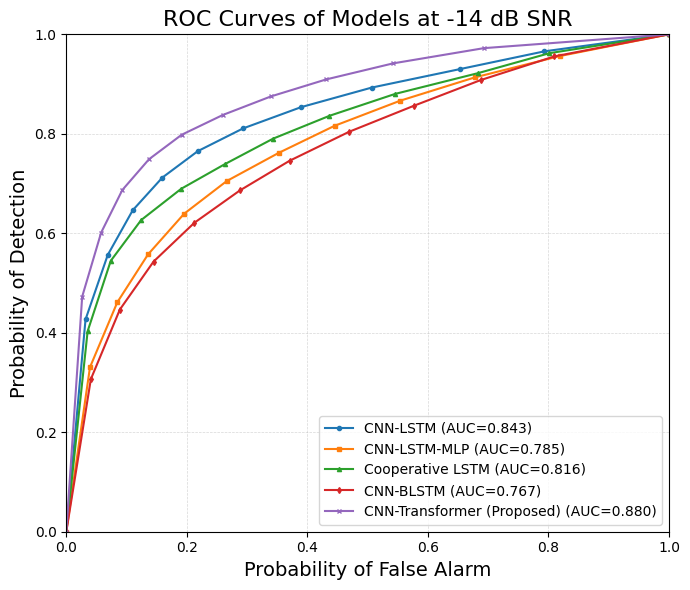

In [10]:
# Evaluate for SNR = 14

snr_value = 14

Xc14_test = Xc[f'Xc{snr_value}_testX']
Xc14_testP = Xcp[f'Xc{snr_value}_testP']

S = 4
Sp = 3

# Split data for CNN/LSTM models
idx = np.arange(S+1) * int(Xc14_test.shape[0] / S)

Xu_test = Xc14_test[idx[0]:idx[1]]
Xx_test = Xc14_test[idx[1]:idx[2]]
Xy_test = Xc14_test[idx[2]:idx[3]]
Xz_test = Xc14_test[idx[3]:idx[4]]

# Slice corresponding labels
Y14_test = Yc_test[idx[0]:idx[4]]

# Split data for Cooperative model
pidx = np.arange(Sp+1) * int(Xc14_testP.shape[0] / Sp)

Xx_testP = Xc14_testP[pidx[0]:pidx[1]]
Xy_testP = Xc14_testP[pidx[1]:pidx[2]]
Xz_testP = Xc14_testP[pidx[2]:pidx[3]]

# Slice cooperative labels
Y10_testP = Yc_testP[pidx[0]:pidx[3]]

# ==============================
# Predictions
# ==============================
X_transformer_input = np.concatenate([Xu_test, Xx_test, Xy_test, Xz_test], axis=-1)
y_CNN_Transformer_model = CNN_Transformer.predict(X_transformer_input)
y_CLSTM = CLSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_LSTM = LSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_Coop = Coop_model.predict([Xx_testP, Xy_testP, Xz_testP])
y_Cnn_blstm = Cnn_blstm.predict([Xu_test, Xx_test, Xy_test, Xz_test])


# ==============================
# ROC Calculation
# ==============================
fp5, tp5, _ = roc_curve(Y14_test[:,1], y_CNN_Transformer_model[:,1])
fp, tp, _ = roc_curve(Y14_test[:,1], y_CLSTM[:,1])
fp1, tp1, _ = roc_curve(Y14_test[:,1], y_LSTM[:,1])
fp3, tp3, _ = roc_curve(Y14_testP[:,1], y_Coop[:,1])
fp4, tp4, _ = roc_curve(Y14_test[:,1], y_Cnn_blstm[:,1])


roc_auc = auc(fp, tp)
roc_auc1 = auc(fp1, tp1)
roc_auc3 = auc(fp3, tp3)
roc_auc4 = auc(fp4, tp4)
roc_auc5 = auc(fp5, tp5)

import numpy as np
import matplotlib.pyplot as plt

# Number of points to display on each ROC curve
n_points = 12

plt.figure(figsize=(7, 6))



# -------- CNN-LSTM --------
idx = np.linspace(0, len(fp)-1, n_points).astype(int)
plt.plot(fp[idx], tp[idx],
         '-o', markersize=3,
         label=f'CNN-LSTM (AUC={roc_auc:.3f})')

# -------- CNN-LSTM-MLP --------
idx = np.linspace(0, len(fp1)-1, n_points).astype(int)
plt.plot(fp1[idx], tp1[idx],
         '-s', markersize=3,
         label=f'CNN-LSTM-MLP (AUC={roc_auc1:.3f})')

# -------- Cooperative LSTM --------
idx = np.linspace(0, len(fp3)-1, n_points).astype(int)
plt.plot(fp3[idx], tp3[idx],
         '-^', markersize=3,
         label=f'Cooperative LSTM (AUC={roc_auc3:.3f})')

# -------- CNN-BLSTM --------
idx = np.linspace(0, len(fp4)-1, n_points).astype(int)
plt.plot(fp4[idx], tp4[idx],
         '-d', markersize=3,
         label=f'CNN-BLSTM (AUC={roc_auc4:.3f})')
# -------- CNN-Transformer --------
idx = np.linspace(0, len(fp5)-1, n_points).astype(int)
plt.plot(fp5[idx], tp5[idx],
         '-x', markersize=3,
         label=f'CNN-Transformer (Proposed) (AUC={roc_auc5:.3f})')


# Figure settings
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel('Probability of False Alarm', fontsize=14)
plt.ylabel('Probability of Detection', fontsize=14)
plt.title('ROC Curves of Models at -14 dB SNR', fontsize=16)

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

plt.legend(loc='lower right', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()


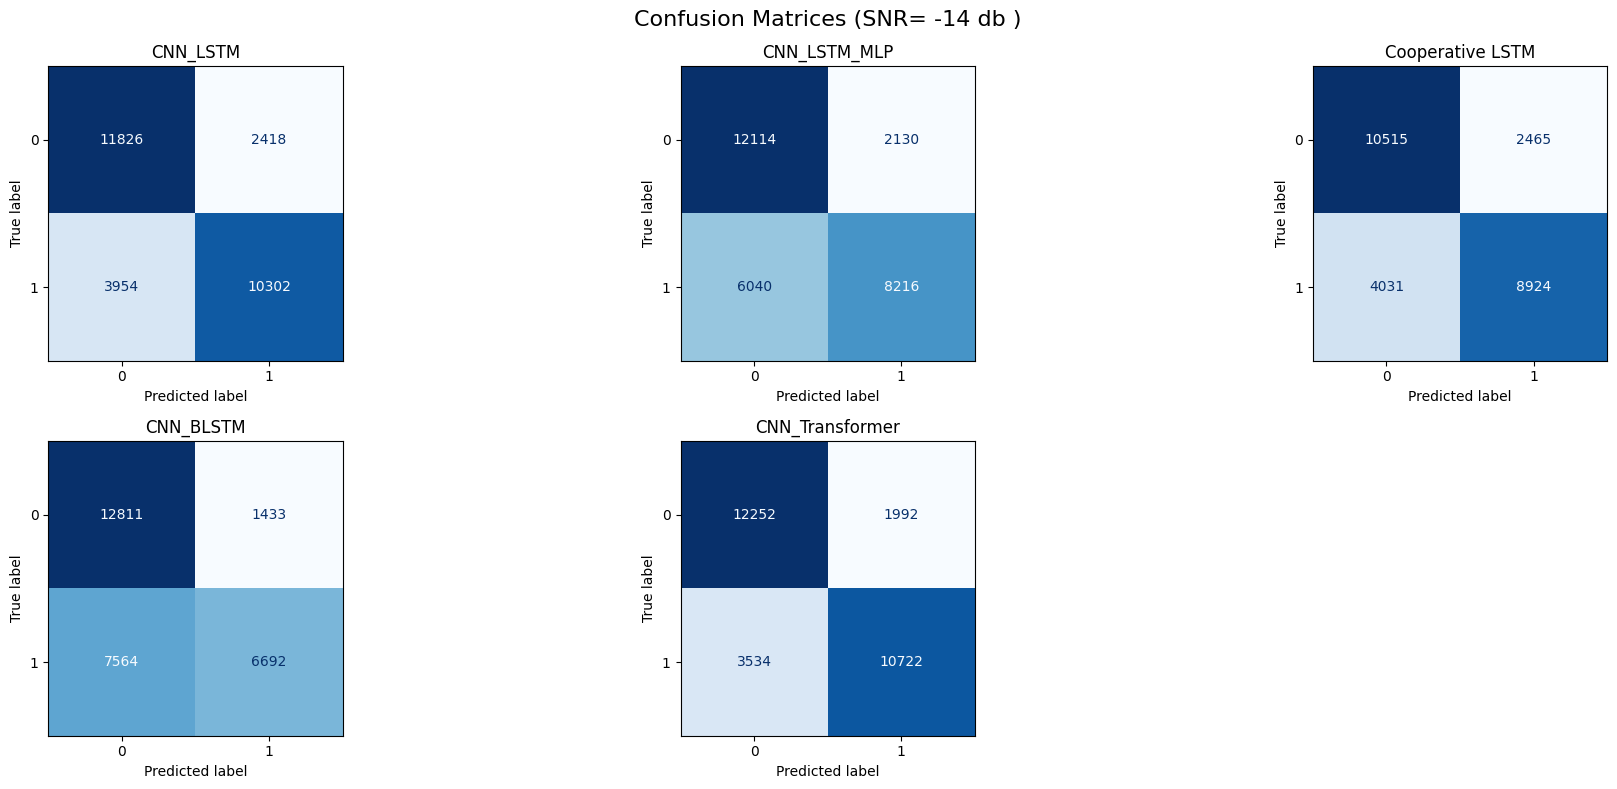

In [11]:
from matplotlib import cm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# ==============================
# Settings
# ==============================
snr_value = 14
threshold = 0.5

# ==============================
# Load Test Data
# ==============================
X_test = Xc[f'Xc{snr_value}_testX']

S = 4
idx = np.arange(S+1) * int(X_test.shape[0] / S)

Xu = X_test[idx[0]:idx[1]]
Xx = X_test[idx[1]:idx[2]]
Xy = X_test[idx[2]:idx[3]]
Xz = X_test[idx[3]:idx[4]]

Y_slice = Yc_test[idx[0]:idx[4]]

# ==============================
# Predictions for each model
# ==============================
y_CLSTM = CLSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_LSTM  = LSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_Cnn_blstm = Cnn_blstm.predict([Xu, Xx, Xy, Xz], verbose=0)

# Concatenate inputs for CNN_Transformer model which expects a single input
X_transformer_input = np.concatenate([Xu, Xx, Xy, Xz], axis=-1)
y_transformer_model = CNN_Transformer.predict(X_transformer_input, verbose=0)


# Cooperative model (separate input)
X_testP = Xcp[f'Xc{snr_value}_testP']
Sp = 3
pidx = np.arange(Sp+1) * int(X_testP.shape[0] / Sp)

XxP = X_testP[pidx[0]:pidx[1]]
XyP = X_testP[pidx[1]:pidx[2]]
XzP = X_testP[pidx[2]:pidx[3]]

Y_sliceP = Yc_testP[pidx[0]:pidx[3]]

y_Coop = Coop_model.predict([XxP, XyP, XzP], verbose=0)

# ==============================
# Convert to class labels

y_true  = Y_slice[:,1].astype(int)
y_trueP = Y_sliceP[:,1].astype(int)

y_pred_CLSTM = (y_CLSTM[:,1] >= threshold).astype(int)
y_pred_LSTM  = (y_LSTM[:,1] >= threshold).astype(int)
y_pred_Coop  = (y_Coop[:,1] >= threshold).astype(int)
y_pred_Cnn_blstm = (y_Cnn_blstm[:,1] >= threshold).astype(int)
y_pred_transformer = (y_transformer_model[:,1] >= threshold).astype(int)


# ==============================
# Confusion Matrices
# ==============================
cm_CLSTM = confusion_matrix(y_true, y_pred_CLSTM)
cm_LSTM  = confusion_matrix(y_true, y_pred_LSTM)
cm_Coop  = confusion_matrix(y_trueP, y_pred_Coop)
cm_Cnn_blstm = confusion_matrix(y_true, y_pred_Cnn_blstm)
cm_transformer = confusion_matrix(y_true, y_pred_transformer)

# ==============================
# Plot All Together
# ==============================
fig, axes = plt.subplots(2, 3, figsize=(20,8))

# CNN-LSTM
ConfusionMatrixDisplay(cm_CLSTM).plot(ax=axes[0, 0], cmap='Blues',values_format='d', colorbar=False)
axes[0, 0].set_title("CNN_LSTM")

# CNN-LSTM-MLP
ConfusionMatrixDisplay(cm_LSTM).plot(ax=axes[0, 1], cmap='Blues', colorbar=False)
axes[0, 1].set_title("CNN_LSTM_MLP")

# Cooperative LSTM
ConfusionMatrixDisplay(cm_Coop).plot(ax=axes[0, 2], cmap='Blues', colorbar=False)
axes[0, 2].set_title("Cooperative LSTM")

#cnn-BLSTM
ConfusionMatrixDisplay(cm_Cnn_blstm).plot(ax=axes[1, 0], cmap='Blues', colorbar=False)
axes[1, 0].set_title("CNN_BLSTM")

# CNN- Transformer
ConfusionMatrixDisplay(cm_transformer).plot(ax=axes[1, 1], cmap='Blues', colorbar=False)
axes[1, 1].set_title("CNN_Transformer")

# Remove the empty subplot at (1,2)
fig.delaxes(axes[1, 2])

plt.suptitle(f"Confusion Matrices (SNR= -14 db )", fontsize=16)
plt.tight_layout()
plt.show()

891/891 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 32s 36ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 37s 41ms/step
811/811 ━━━━━━━━━━━━━━━━━━━━ 34s 42ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step


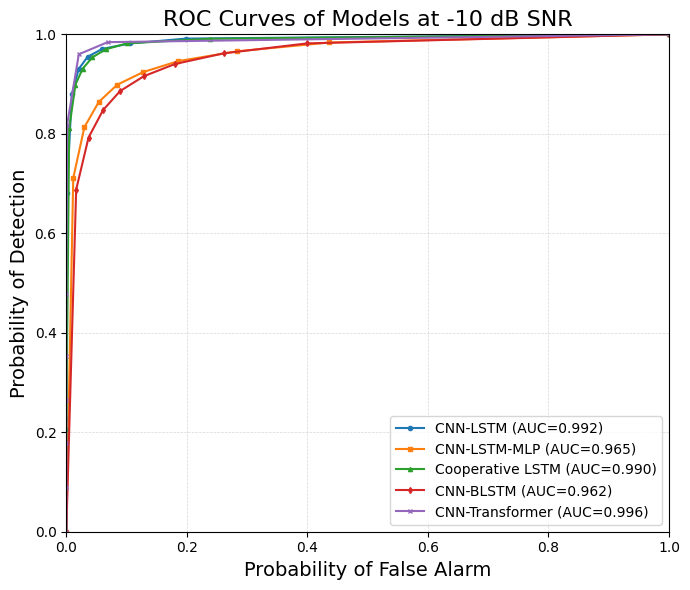

In [12]:

# Evaluate for SNR = 10

snr_value = 10

Xc10_test = Xc[f'Xc{snr_value}_testX']
Xc10_testP = Xcp[f'Xc{snr_value}_testP']

S = 4
Sp = 3

# Split data for CNN/LSTM models
idx = np.arange(S+1) * int(Xc10_test.shape[0] / S)

Xu_test = Xc10_test[idx[0]:idx[1]]
Xx_test = Xc10_test[idx[1]:idx[2]]
Xy_test = Xc10_test[idx[2]:idx[3]]
Xz_test = Xc10_test[idx[3]:idx[4]]

# Slice corresponding labels
Y10_test = Yc_test[idx[0]:idx[4]]

# Split data for Cooperative model
pidx = np.arange(Sp+1) * int(Xc10_testP.shape[0] / Sp)

Xx_testP = Xc10_testP[pidx[0]:pidx[1]]
Xy_testP = Xc10_testP[pidx[1]:pidx[2]]
Xz_testP = Xc10_testP[pidx[2]:pidx[3]]

# Slice cooperative labels
Y10_testP = Yc_testP[pidx[0]:pidx[3]]

# ==============================
# Predictions
# ==============================
X_transformer_input = np.concatenate([Xu_test, Xx_test, Xy_test, Xz_test], axis=-1)
y_CNN_Transformer_model = CNN_Transformer.predict(X_transformer_input)
y_CLSTM = CLSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_LSTM = LSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_Coop = Coop_model.predict([Xx_testP, Xy_testP, Xz_testP])
y_Cnn_blstm = Cnn_blstm.predict([Xu_test, Xx_test, Xy_test, Xz_test])


# ==============================
# ROC Calculation
# ==============================
fp5, tp5, _ = roc_curve(Y10_test[:,1], y_CNN_Transformer_model[:,1])
fp, tp, _ = roc_curve(Y10_test[:,1], y_CLSTM[:,1])
fp1, tp1, _ = roc_curve(Y10_test[:,1], y_LSTM[:,1])
fp3, tp3, _ = roc_curve(Y10_testP[:,1], y_Coop[:,1])
fp4, tp4, _ = roc_curve(Y10_test[:,1], y_Cnn_blstm[:,1])


roc_auc = auc(fp, tp)
roc_auc1 = auc(fp1, tp1)
roc_auc3 = auc(fp3, tp3)
roc_auc4 = auc(fp4, tp4)
roc_auc5 = auc(fp5, tp5)

import numpy as np
import matplotlib.pyplot as plt

# Number of points to display on each ROC curve
n_points = 10

plt.figure(figsize=(7, 6))



# -------- CNN-LSTM --------
idx = np.linspace(0, len(fp)-1, n_points).astype(int)
plt.plot(fp[idx], tp[idx],
         '-o', markersize=3,
         label=f'CNN-LSTM (AUC={roc_auc:.3f})')

# -------- CNN-LSTM-MLP --------
idx = np.linspace(0, len(fp1)-1, n_points).astype(int)
plt.plot(fp1[idx], tp1[idx],
         '-s', markersize=3,
         label=f'CNN-LSTM-MLP (AUC={roc_auc1:.3f})')

# -------- Cooperative LSTM --------
idx = np.linspace(0, len(fp3)-1, n_points).astype(int)
plt.plot(fp3[idx], tp3[idx],
         '-^', markersize=3,
         label=f'Cooperative LSTM (AUC={roc_auc3:.3f})')

# -------- CNN-BLSTM --------
idx = np.linspace(0, len(fp4)-1, n_points).astype(int)
plt.plot(fp4[idx], tp4[idx],
         '-d', markersize=3,
         label=f'CNN-BLSTM (AUC={roc_auc4:.3f})')

# -------- CNN-Transformer --------
idx = np.linspace(0, len(fp5)-1, n_points).astype(int)
plt.plot(fp5[idx], tp5[idx],
         '-x', markersize=3,
         label=f'CNN-Transformer (AUC={roc_auc5:.3f})')

# Figure settings
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel('Probability of False Alarm', fontsize=14)
plt.ylabel('Probability of Detection', fontsize=14)
plt.title('ROC Curves of Models at -10 dB SNR', fontsize=16)

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

plt.legend(loc='lower right', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()



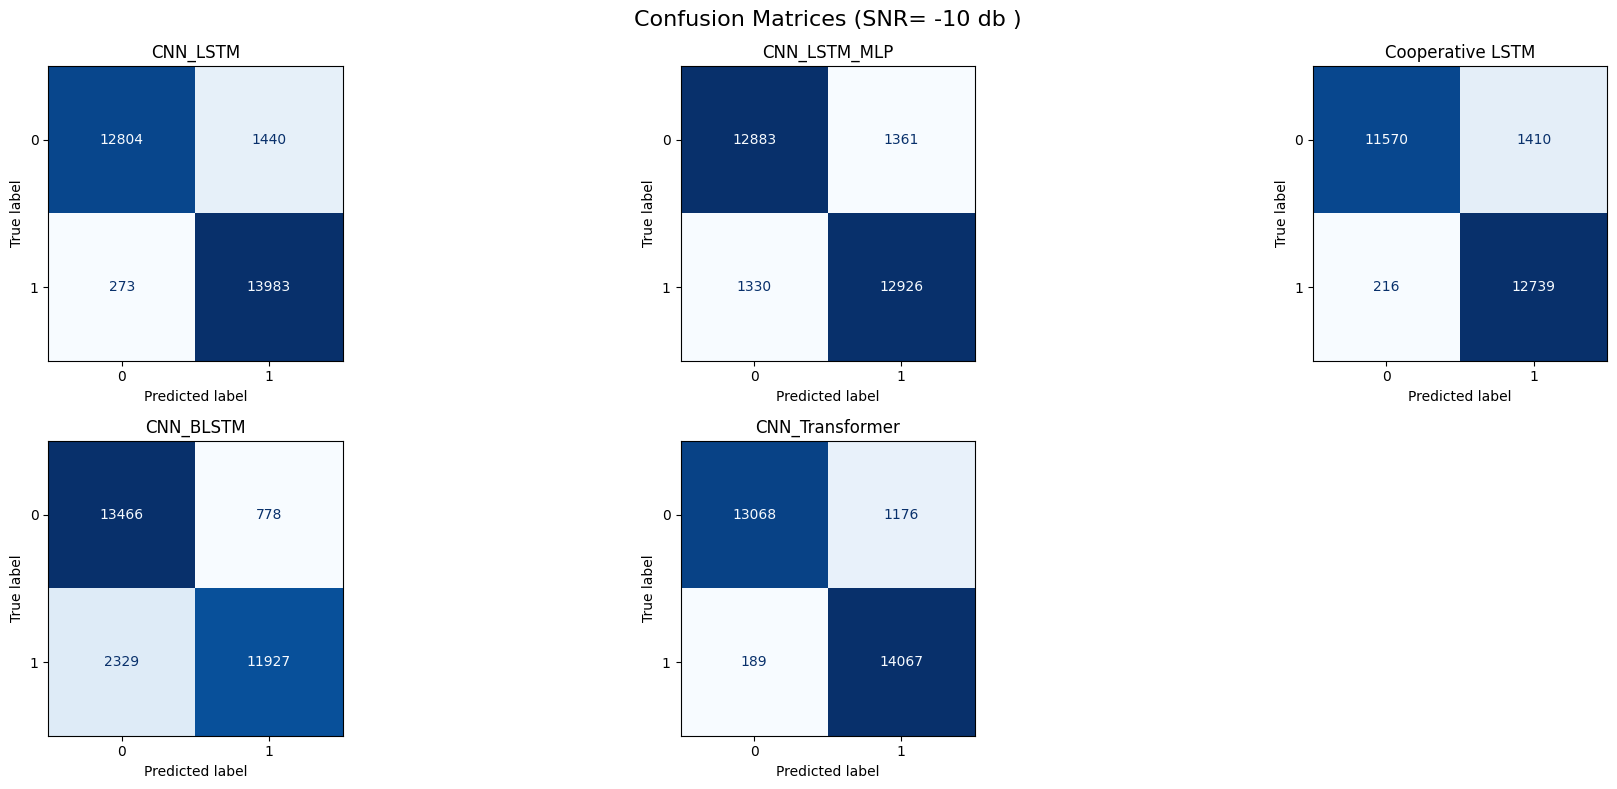

In [13]:
from matplotlib import cm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# ==============================
# Settings
# ==============================
snr_value = 10
threshold = 0.5

# ==============================
# Load Test Data
# ==============================
X_test = Xc[f'Xc{snr_value}_testX']

S = 4
idx = np.arange(S+1) * int(X_test.shape[0] / S)

Xu = X_test[idx[0]:idx[1]]
Xx = X_test[idx[1]:idx[2]]
Xy = X_test[idx[2]:idx[3]]
Xz = X_test[idx[3]:idx[4]]

Y_slice = Yc_test[idx[0]:idx[4]]

# ==============================
# Predictions for each model
# ==============================
y_CLSTM = CLSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_LSTM  = LSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_Cnn_blstm = Cnn_blstm.predict([Xu, Xx, Xy, Xz], verbose=0)

# Concatenate inputs for CNN_Transformer model which expects a single input
X_transformer_input = np.concatenate([Xu, Xx, Xy, Xz], axis=-1)
y_transformer_model = CNN_Transformer.predict(X_transformer_input, verbose=0)


# Cooperative model (separate input)
X_testP = Xcp[f'Xc{snr_value}_testP']
Sp = 3
pidx = np.arange(Sp+1) * int(X_testP.shape[0] / Sp)

XxP = X_testP[pidx[0]:pidx[1]]
XyP = X_testP[pidx[1]:pidx[2]]
XzP = X_testP[pidx[2]:pidx[3]]

Y_sliceP = Yc_testP[pidx[0]:pidx[3]]

y_Coop = Coop_model.predict([XxP, XyP, XzP], verbose=0)

# ==============================
# Convert to class labels

y_true  = Y_slice[:,1].astype(int)
y_trueP = Y_sliceP[:,1].astype(int)

y_pred_CLSTM = (y_CLSTM[:,1] >= threshold).astype(int)
y_pred_LSTM  = (y_LSTM[:,1] >= threshold).astype(int)
y_pred_Coop  = (y_Coop[:,1] >= threshold).astype(int)
y_pred_Cnn_blstm = (y_Cnn_blstm[:,1] >= threshold).astype(int)
y_pred_transformer = (y_transformer_model[:,1] >= threshold).astype(int)


# ==============================
# Confusion Matrices
# ==============================
cm_CLSTM = confusion_matrix(y_true, y_pred_CLSTM)
cm_LSTM  = confusion_matrix(y_true, y_pred_LSTM)
cm_Coop  = confusion_matrix(y_trueP, y_pred_Coop)
cm_Cnn_blstm = confusion_matrix(y_true, y_pred_Cnn_blstm)
cm_transformer = confusion_matrix(y_true, y_pred_transformer)

# ==============================
# Plot All Together
# ==============================
fig, axes = plt.subplots(2, 3, figsize=(20,8))

# CNN-LSTM
ConfusionMatrixDisplay(cm_CLSTM).plot(ax=axes[0, 0], cmap='Blues', colorbar=False)
axes[0, 0].set_title("CNN_LSTM")

# CNN-LSTM-MLP
ConfusionMatrixDisplay(cm_LSTM).plot(ax=axes[0, 1], cmap='Blues', colorbar=False)
axes[0, 1].set_title("CNN_LSTM_MLP")

# Cooperative LSTM
ConfusionMatrixDisplay(cm_Coop).plot(ax=axes[0, 2], cmap='Blues', colorbar=False)
axes[0, 2].set_title("Cooperative LSTM")

#cnn-BLSTM
ConfusionMatrixDisplay(cm_Cnn_blstm).plot(ax=axes[1, 0], cmap='Blues', colorbar=False)
axes[1, 0].set_title("CNN_BLSTM")

# CNN- Transformer
ConfusionMatrixDisplay(cm_transformer).plot(ax=axes[1, 1], cmap='Blues', colorbar=False)
axes[1, 1].set_title("CNN_Transformer")

# Remove the empty subplot at (1,2)
fig.delaxes(axes[1, 2])

plt.suptitle(f"Confusion Matrices (SNR= -10 db )", fontsize=16)
plt.tight_layout()
plt.show()

891/891 ━━━━━━━━━━━━━━━━━━━━ 31s 34ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 34s 38ms/step
811/811 ━━━━━━━━━━━━━━━━━━━━ 35s 44ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step


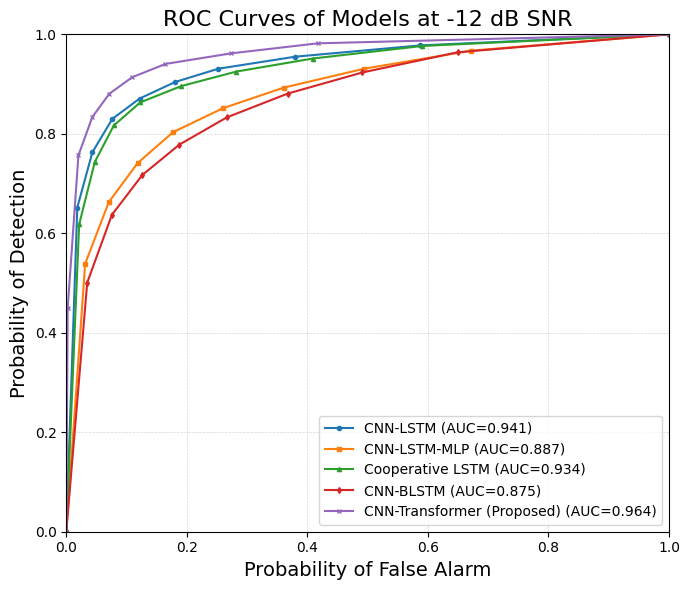

In [14]:
# ==============================
# Evaluate for SNR = -12 dB
# ==============================

snr_value = 12      # Xc12 corresponds to -12 dB

Xc12_test = Xc[f'Xc{snr_value}_testX']
Xc12_testP = Xcp[f'Xc{snr_value}_testP']

S = 4
Sp = 3

# Split data for CNN/LSTM models
idx = np.arange(S+1) * int(Xc12_test.shape[0] / S)

Xu_test = Xc12_test[idx[0]:idx[1]]
Xx_test = Xc12_test[idx[1]:idx[2]]
Xy_test = Xc12_test[idx[2]:idx[3]]
Xz_test = Xc12_test[idx[3]:idx[4]]

# Slice corresponding labels
Y12_test = Yc_test[idx[0]:idx[4]]

# Split data for Cooperative model
pidx = np.arange(Sp+1) * int(Xc12_testP.shape[0] / Sp)

Xx_testP = Xc12_testP[pidx[0]:pidx[1]]
Xy_testP = Xc12_testP[pidx[1]:pidx[2]]
Xz_testP = Xc12_testP[pidx[2]:pidx[3]]

# Slice cooperative labels
Y12_testP = Yc_testP[pidx[0]:pidx[3]]

# ==============================
# Predictions
# ==============================
y_CLSTM = CLSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_LSTM = LSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_Coop = Coop_model.predict([Xx_testP, Xy_testP, Xz_testP])
y_Cnn_blstm = Cnn_blstm.predict([Xu_test, Xx_test, Xy_test, Xz_test])

X_transformer_input = np.concatenate([Xu_test, Xx_test, Xy_test, Xz_test], axis=-1)
y_CNN_Transformer_model = CNN_Transformer.predict(X_transformer_input)

# ==============================
# ROC Calculation
# ==============================
fp, tp, _ = roc_curve(Y12_test[:,1], y_CLSTM[:,1])
fp1, tp1, _ = roc_curve(Y12_test[:,1], y_LSTM[:,1])
fp3, tp3, _ = roc_curve(Y12_testP[:,1], y_Coop[:,1])
fp4, tp4, _ = roc_curve(Y12_test[:,1], y_Cnn_blstm[:,1])
fp5, tp5, _ = roc_curve(Y12_test[:,1], y_CNN_Transformer_model[:,1])

roc_auc = auc(fp, tp)
roc_auc1 = auc(fp1, tp1)
roc_auc3 = auc(fp3, tp3)
roc_auc4 = auc(fp4, tp4)
roc_auc5 = auc(fp5, tp5)

import numpy as np
import matplotlib.pyplot as plt

# Number of points to display on each ROC curve
n_points = 10

plt.figure(figsize=(7, 6))

# -------- CNN-LSTM --------
idx = np.linspace(0, len(fp)-1, n_points).astype(int)
plt.plot(fp[idx], tp[idx],
         '-o', markersize=3,
         label=f'CNN-LSTM (AUC={roc_auc:.3f})')

# -------- CNN-LSTM-MLP --------
idx = np.linspace(0, len(fp1)-1, n_points).astype(int)
plt.plot(fp1[idx], tp1[idx],
         '-s', markersize=3,
         label=f'CNN-LSTM-MLP (AUC={roc_auc1:.3f})')

# -------- Cooperative LSTM --------
idx = np.linspace(0, len(fp3)-1, n_points).astype(int)
plt.plot(fp3[idx], tp3[idx],
         '-^', markersize=3,
         label=f'Cooperative LSTM (AUC={roc_auc3:.3f})')

# -------- CNN-BLSTM --------
idx = np.linspace(0, len(fp4)-1, n_points).astype(int)
plt.plot(fp4[idx], tp4[idx],
         '-d', markersize=3,
         label=f'CNN-BLSTM (AUC={roc_auc4:.3f})')

# -------- CNN-Transformer --------
idx = np.linspace(0, len(fp5)-1, n_points).astype(int)
plt.plot(fp5[idx], tp5[idx],
         '-x', markersize=3,
         label=f'CNN-Transformer (Proposed) (AUC={roc_auc5:.3f})')

# Figure settings
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel('Probability of False Alarm', fontsize=14)
plt.ylabel('Probability of Detection', fontsize=14)
plt.title('ROC Curves of Models at -12 dB SNR', fontsize=16)

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

plt.legend(loc='lower right', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

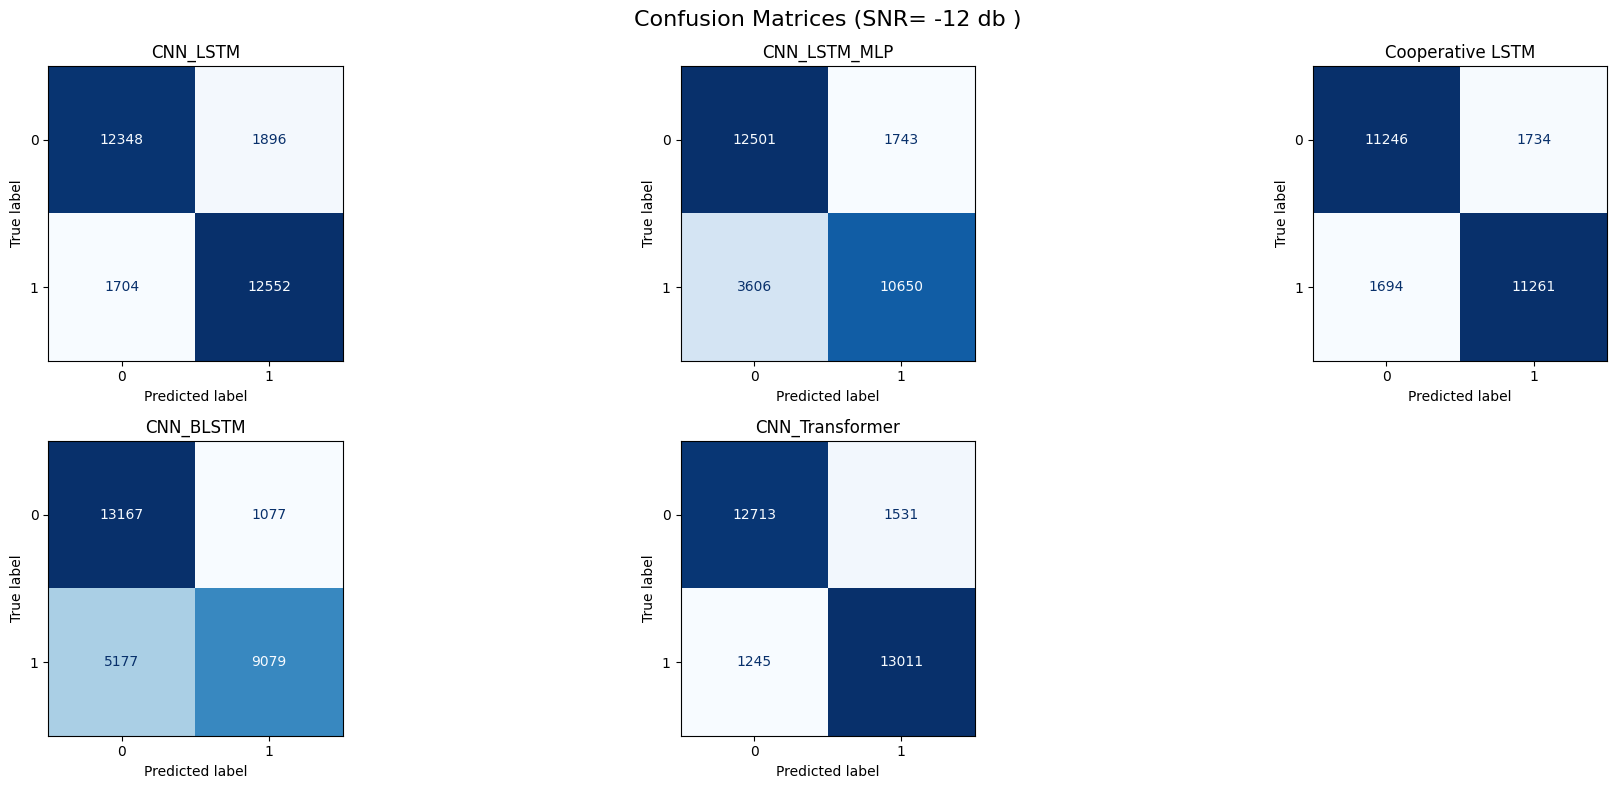

In [15]:
from matplotlib import cm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# ==============================
# Settings
# ==============================
snr_value = 12
threshold = 0.5

# ==============================
# Load Test Data
# ==============================
X_test = Xc[f'Xc{snr_value}_testX']

S = 4
idx = np.arange(S+1) * int(X_test.shape[0] / S)

Xu = X_test[idx[0]:idx[1]]
Xx = X_test[idx[1]:idx[2]]
Xy = X_test[idx[2]:idx[3]]
Xz = X_test[idx[3]:idx[4]]

Y_slice = Yc_test[idx[0]:idx[4]]

# ==============================
# Predictions for each model
# ==============================
y_CLSTM = CLSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_LSTM  = LSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_Cnn_blstm = Cnn_blstm.predict([Xu, Xx, Xy, Xz], verbose=0)

# Concatenate inputs for CNN_Transformer model which expects a single input
X_transformer_input = np.concatenate([Xu, Xx, Xy, Xz], axis=-1)
y_transformer_model = CNN_Transformer.predict(X_transformer_input, verbose=0)


# Cooperative model (separate input)
X_testP = Xcp[f'Xc{snr_value}_testP']
Sp = 3
pidx = np.arange(Sp+1) * int(X_testP.shape[0] / Sp)

XxP = X_testP[pidx[0]:pidx[1]]
XyP = X_testP[pidx[1]:pidx[2]]
XzP = X_testP[pidx[2]:pidx[3]]

Y_sliceP = Yc_testP[pidx[0]:pidx[3]]

y_Coop = Coop_model.predict([XxP, XyP, XzP], verbose=0)

# ==============================
# Convert to class labels

y_true  = Y_slice[:,1].astype(int)
y_trueP = Y_sliceP[:,1].astype(int)

y_pred_CLSTM = (y_CLSTM[:,1] >= threshold).astype(int)
y_pred_LSTM  = (y_LSTM[:,1] >= threshold).astype(int)
y_pred_Coop  = (y_Coop[:,1] >= threshold).astype(int)
y_pred_Cnn_blstm = (y_Cnn_blstm[:,1] >= threshold).astype(int)
y_pred_transformer = (y_transformer_model[:,1] >= threshold).astype(int)


# ==============================
# Confusion Matrices
# ==============================
cm_CLSTM = confusion_matrix(y_true, y_pred_CLSTM)
cm_LSTM  = confusion_matrix(y_true, y_pred_LSTM)
cm_Coop  = confusion_matrix(y_trueP, y_pred_Coop)
cm_Cnn_blstm = confusion_matrix(y_true, y_pred_Cnn_blstm)
cm_transformer = confusion_matrix(y_true, y_pred_transformer)

# ==============================
# Plot All Together
# ==============================
fig, axes = plt.subplots(2, 3, figsize=(20,8))

# CNN-LSTM
ConfusionMatrixDisplay(cm_CLSTM).plot(ax=axes[0, 0], cmap='Blues', colorbar=False)
axes[0, 0].set_title("CNN_LSTM")

# CNN-LSTM-MLP
ConfusionMatrixDisplay(cm_LSTM).plot(ax=axes[0, 1], cmap='Blues', colorbar=False)
axes[0, 1].set_title("CNN_LSTM_MLP")

# Cooperative LSTM
ConfusionMatrixDisplay(cm_Coop).plot(ax=axes[0, 2], cmap='Blues', colorbar=False)
axes[0, 2].set_title("Cooperative LSTM")

#cnn-BLSTM
ConfusionMatrixDisplay(cm_Cnn_blstm).plot(ax=axes[1, 0], cmap='Blues', colorbar=False)
axes[1, 0].set_title("CNN_BLSTM")

# CNN- Transformer
ConfusionMatrixDisplay(cm_transformer).plot(ax=axes[1, 1], cmap='Blues', colorbar=False)
axes[1, 1].set_title("CNN_Transformer")

# Remove the empty subplot at (1,2)
fig.delaxes(axes[1, 2])

plt.suptitle(f"Confusion Matrices (SNR= -12 db )", fontsize=16)
plt.tight_layout()
plt.show()

891/891 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 36s 41ms/step
811/811 ━━━━━━━━━━━━━━━━━━━━ 36s 44ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 32s 36ms/step


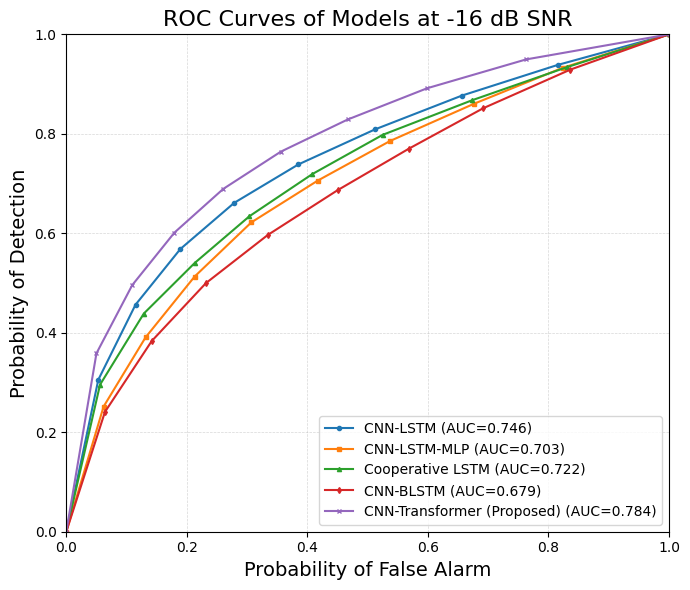

In [16]:
# ==============================
# Evaluate for SNR = -16 dB
# ==============================

snr_value = 16      # Xc16 corresponds to -16 dB

Xc16_test = Xc[f'Xc{snr_value}_testX']
Xc16_testP = Xcp[f'Xc{snr_value}_testP']

S = 4
Sp = 3

# Split data for CNN/LSTM models
idx = np.arange(S+1) * int(Xc16_test.shape[0] / S)

Xu_test = Xc16_test[idx[0]:idx[1]]
Xx_test = Xc16_test[idx[1]:idx[2]]
Xy_test = Xc16_test[idx[2]:idx[3]]
Xz_test = Xc16_test[idx[3]:idx[4]]

# Slice corresponding labels
Y16_test = Yc_test[idx[0]:idx[4]]

# Split data for Cooperative model
pidx = np.arange(Sp+1) * int(Xc16_testP.shape[0] / Sp)

Xx_testP = Xc16_testP[pidx[0]:pidx[1]]
Xy_testP = Xc16_testP[pidx[1]:pidx[2]]
Xz_testP = Xc16_testP[pidx[2]:pidx[3]]

# Slice cooperative labels
Y16_testP = Yc_testP[pidx[0]:pidx[3]]

# ==============================
# Predictions
# ==============================
y_CLSTM = CLSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_LSTM = LSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_Coop = Coop_model.predict([Xx_testP, Xy_testP, Xz_testP])
y_Cnn_blstm = Cnn_blstm.predict([Xu_test, Xx_test, Xy_test, Xz_test])

X_transformer_input = np.concatenate([Xu_test, Xx_test, Xy_test, Xz_test], axis=-1)
y_CNN_Transformer_model = CNN_Transformer.predict(X_transformer_input)

# ==============================
# ROC Calculation
# ==============================
fp, tp, _ = roc_curve(Y16_test[:,1], y_CLSTM[:,1])
fp1, tp1, _ = roc_curve(Y16_test[:,1], y_LSTM[:,1])
fp3, tp3, _ = roc_curve(Y16_testP[:,1], y_Coop[:,1])
fp4, tp4, _ = roc_curve(Y16_test[:,1], y_Cnn_blstm[:,1])
fp5, tp5, _ = roc_curve(Y16_test[:,1], y_CNN_Transformer_model[:,1])

roc_auc = auc(fp, tp)
roc_auc1 = auc(fp1, tp1)
roc_auc3 = auc(fp3, tp3)
roc_auc4 = auc(fp4, tp4)
roc_auc5 = auc(fp5, tp5)

import numpy as np
import matplotlib.pyplot as plt

# Number of points to display on each ROC curve
n_points = 10

plt.figure(figsize=(7, 6))

# -------- CNN-LSTM --------
idx = np.linspace(0, len(fp)-1, n_points).astype(int)
plt.plot(fp[idx], tp[idx],
         '-o', markersize=3,
         label=f'CNN-LSTM (AUC={roc_auc:.3f})')

# -------- CNN-LSTM-MLP --------
idx = np.linspace(0, len(fp1)-1, n_points).astype(int)
plt.plot(fp1[idx], tp1[idx],
         '-s', markersize=3,
         label=f'CNN-LSTM-MLP (AUC={roc_auc1:.3f})')

# -------- Cooperative LSTM --------
idx = np.linspace(0, len(fp3)-1, n_points).astype(int)
plt.plot(fp3[idx], tp3[idx],
         '-^', markersize=3,
         label=f'Cooperative LSTM (AUC={roc_auc3:.3f})')

# -------- CNN-BLSTM --------
idx = np.linspace(0, len(fp4)-1, n_points).astype(int)
plt.plot(fp4[idx], tp4[idx],
         '-d', markersize=3,
         label=f'CNN-BLSTM (AUC={roc_auc4:.3f})')

# -------- CNN-Transformer --------
idx = np.linspace(0, len(fp5)-1, n_points).astype(int)
plt.plot(fp5[idx], tp5[idx],
         '-x', markersize=3,
         label=f'CNN-Transformer (Proposed) (AUC={roc_auc5:.3f})')

# Figure settings
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel('Probability of False Alarm', fontsize=14)
plt.ylabel('Probability of Detection', fontsize=14)
plt.title('ROC Curves of Models at -16 dB SNR', fontsize=16)

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

plt.legend(loc='lower right', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

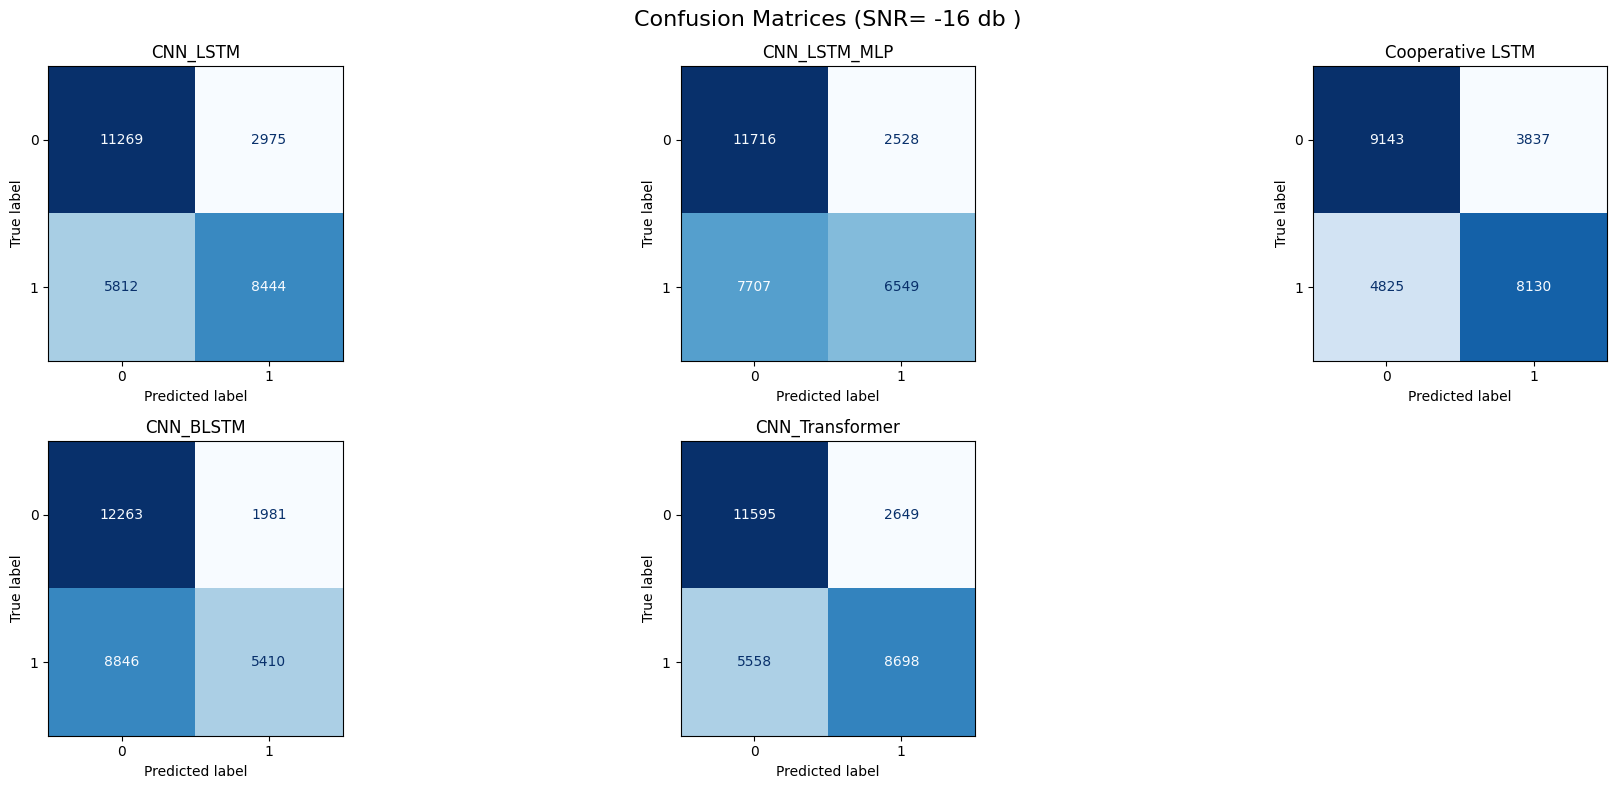

In [17]:
from matplotlib import cm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# ==============================
# Settings
# ==============================
snr_value = 16
threshold = 0.5

# ==============================
# Load Test Data
# ==============================
X_test = Xc[f'Xc{snr_value}_testX']

S = 4
idx = np.arange(S+1) * int(X_test.shape[0] / S)

Xu = X_test[idx[0]:idx[1]]
Xx = X_test[idx[1]:idx[2]]
Xy = X_test[idx[2]:idx[3]]
Xz = X_test[idx[3]:idx[4]]

Y_slice = Yc_test[idx[0]:idx[4]]

# ==============================
# Predictions for each model
# ==============================
y_CLSTM = CLSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_LSTM  = LSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_Cnn_blstm = Cnn_blstm.predict([Xu, Xx, Xy, Xz], verbose=0)

# Concatenate inputs for CNN_Transformer model which expects a single input
X_transformer_input = np.concatenate([Xu, Xx, Xy, Xz], axis=-1)
y_transformer_model = CNN_Transformer.predict(X_transformer_input, verbose=0)


# Cooperative model (separate input)
X_testP = Xcp[f'Xc{snr_value}_testP']
Sp = 3
pidx = np.arange(Sp+1) * int(X_testP.shape[0] / Sp)

XxP = X_testP[pidx[0]:pidx[1]]
XyP = X_testP[pidx[1]:pidx[2]]
XzP = X_testP[pidx[2]:pidx[3]]

Y_sliceP = Yc_testP[pidx[0]:pidx[3]]

y_Coop = Coop_model.predict([XxP, XyP, XzP], verbose=0)

# ==============================
# Convert to class labels

y_true  = Y_slice[:,1].astype(int)
y_trueP = Y_sliceP[:,1].astype(int)

y_pred_CLSTM = (y_CLSTM[:,1] >= threshold).astype(int)
y_pred_LSTM  = (y_LSTM[:,1] >= threshold).astype(int)
y_pred_Coop  = (y_Coop[:,1] >= threshold).astype(int)
y_pred_Cnn_blstm = (y_Cnn_blstm[:,1] >= threshold).astype(int)
y_pred_transformer = (y_transformer_model[:,1] >= threshold).astype(int)


# ==============================
# Confusion Matrices
# ==============================
cm_CLSTM = confusion_matrix(y_true, y_pred_CLSTM)
cm_LSTM  = confusion_matrix(y_true, y_pred_LSTM)
cm_Coop  = confusion_matrix(y_trueP, y_pred_Coop)
cm_Cnn_blstm = confusion_matrix(y_true, y_pred_Cnn_blstm)
cm_transformer = confusion_matrix(y_true, y_pred_transformer)

# ==============================
# Plot All Together
# ==============================
fig, axes = plt.subplots(2, 3, figsize=(20,8))

# CNN-LSTM
ConfusionMatrixDisplay(cm_CLSTM).plot(ax=axes[0, 0], cmap='Blues', colorbar=False)
axes[0, 0].set_title("CNN_LSTM")

# CNN-LSTM-MLP
ConfusionMatrixDisplay(cm_LSTM).plot(ax=axes[0, 1], cmap='Blues', colorbar=False)
axes[0, 1].set_title("CNN_LSTM_MLP")

# Cooperative LSTM
ConfusionMatrixDisplay(cm_Coop).plot(ax=axes[0, 2], cmap='Blues', colorbar=False)
axes[0, 2].set_title("Cooperative LSTM")

#cnn-BLSTM
ConfusionMatrixDisplay(cm_Cnn_blstm).plot(ax=axes[1, 0], cmap='Blues', colorbar=False)
axes[1, 0].set_title("CNN_BLSTM")

# CNN- Transformer
ConfusionMatrixDisplay(cm_transformer).plot(ax=axes[1, 1], cmap='Blues', colorbar=False)
axes[1, 1].set_title("CNN_Transformer")

# Remove the empty subplot at (1,2)
fig.delaxes(axes[1, 2])

plt.suptitle(f"Confusion Matrices (SNR= -16 db )", fontsize=16)
plt.tight_layout()
plt.show()

891/891 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 34s 39ms/step
811/811 ━━━━━━━━━━━━━━━━━━━━ 36s 44ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 31s 34ms/step


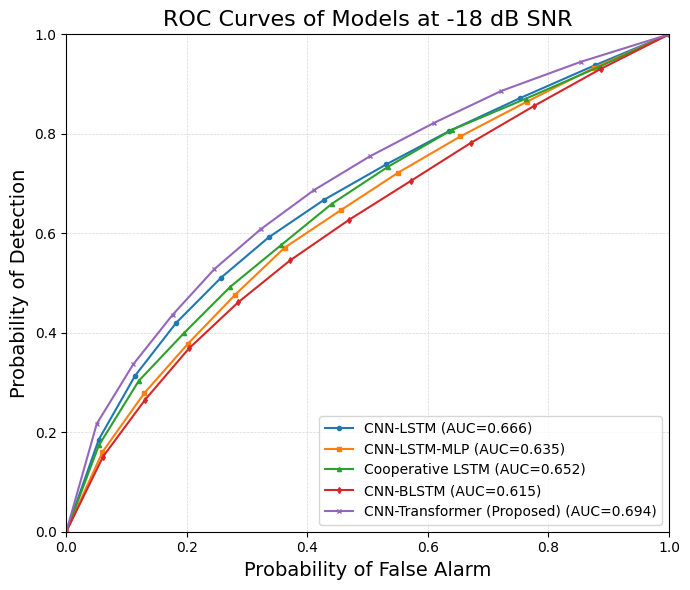

In [18]:
# ==============================
# Evaluate for SNR = -18 dB
# ==============================

snr_value = 18      # Xc18 corresponds to -18 dB

Xc18_test = Xc[f'Xc{snr_value}_testX']
Xc18_testP = Xcp[f'Xc{snr_value}_testP']

S = 4
Sp = 3

# Split data for CNN/LSTM models
idx = np.arange(S+1) * int(Xc18_test.shape[0] / S)

Xu_test = Xc18_test[idx[0]:idx[1]]
Xx_test = Xc18_test[idx[1]:idx[2]]
Xy_test = Xc18_test[idx[2]:idx[3]]
Xz_test = Xc18_test[idx[3]:idx[4]]

# Slice corresponding labels
Y18_test = Yc_test[idx[0]:idx[4]]

# Split data for Cooperative model
pidx = np.arange(Sp+1) * int(Xc16_testP.shape[0] / Sp)

Xx_testP = Xc18_testP[pidx[0]:pidx[1]]
Xy_testP = Xc18_testP[pidx[1]:pidx[2]]
Xz_testP = Xc18_testP[pidx[2]:pidx[3]]

# Slice cooperative labels
Y18_testP = Yc_testP[pidx[0]:pidx[3]]

# ==============================
# Predictions
# ==============================
y_CLSTM = CLSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_LSTM = LSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_Coop = Coop_model.predict([Xx_testP, Xy_testP, Xz_testP])
y_Cnn_blstm = Cnn_blstm.predict([Xu_test, Xx_test, Xy_test, Xz_test])

X_transformer_input = np.concatenate([Xu_test, Xx_test, Xy_test, Xz_test], axis=-1)
y_CNN_Transformer_model = CNN_Transformer.predict(X_transformer_input)

# ==============================
# ROC Calculation
# ==============================
fp, tp, _ = roc_curve(Y18_test[:,1], y_CLSTM[:,1])
fp1, tp1, _ = roc_curve(Y18_test[:,1], y_LSTM[:,1])
fp3, tp3, _ = roc_curve(Y18_testP[:,1], y_Coop[:,1])
fp4, tp4, _ = roc_curve(Y18_test[:,1], y_Cnn_blstm[:,1])
fp5, tp5, _ = roc_curve(Y18_test[:,1], y_CNN_Transformer_model[:,1])

roc_auc = auc(fp, tp)
roc_auc1 = auc(fp1, tp1)
roc_auc3 = auc(fp3, tp3)
roc_auc4 = auc(fp4, tp4)
roc_auc5 = auc(fp5, tp5)

import numpy as np
import matplotlib.pyplot as plt

# Number of points to display on each ROC curve
n_points = 12

plt.figure(figsize=(7, 6))

# -------- CNN-LSTM --------
idx = np.linspace(0, len(fp)-1, n_points).astype(int)
plt.plot(fp[idx], tp[idx],
         '-o', markersize=3,
         label=f'CNN-LSTM (AUC={roc_auc:.3f})')

# -------- CNN-LSTM-MLP --------
idx = np.linspace(0, len(fp1)-1, n_points).astype(int)
plt.plot(fp1[idx], tp1[idx],
         '-s', markersize=3,
         label=f'CNN-LSTM-MLP (AUC={roc_auc1:.3f})')

# -------- Cooperative LSTM --------
idx = np.linspace(0, len(fp3)-1, n_points).astype(int)
plt.plot(fp3[idx], tp3[idx],
         '-^', markersize=3,
         label=f'Cooperative LSTM (AUC={roc_auc3:.3f})')

# -------- CNN-BLSTM --------
idx = np.linspace(0, len(fp4)-1, n_points).astype(int)
plt.plot(fp4[idx], tp4[idx],
         '-d', markersize=3,
         label=f'CNN-BLSTM (AUC={roc_auc4:.3f})')

# -------- CNN-Transformer --------
idx = np.linspace(0, len(fp5)-1, n_points).astype(int)
plt.plot(fp5[idx], tp5[idx],
         '-x', markersize=3,
         label=f'CNN-Transformer (Proposed) (AUC={roc_auc5:.3f})')

# Figure settings
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel('Probability of False Alarm', fontsize=14)
plt.ylabel('Probability of Detection', fontsize=14)
plt.title('ROC Curves of Models at -18 dB SNR', fontsize=16)

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

plt.legend(loc='lower right', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

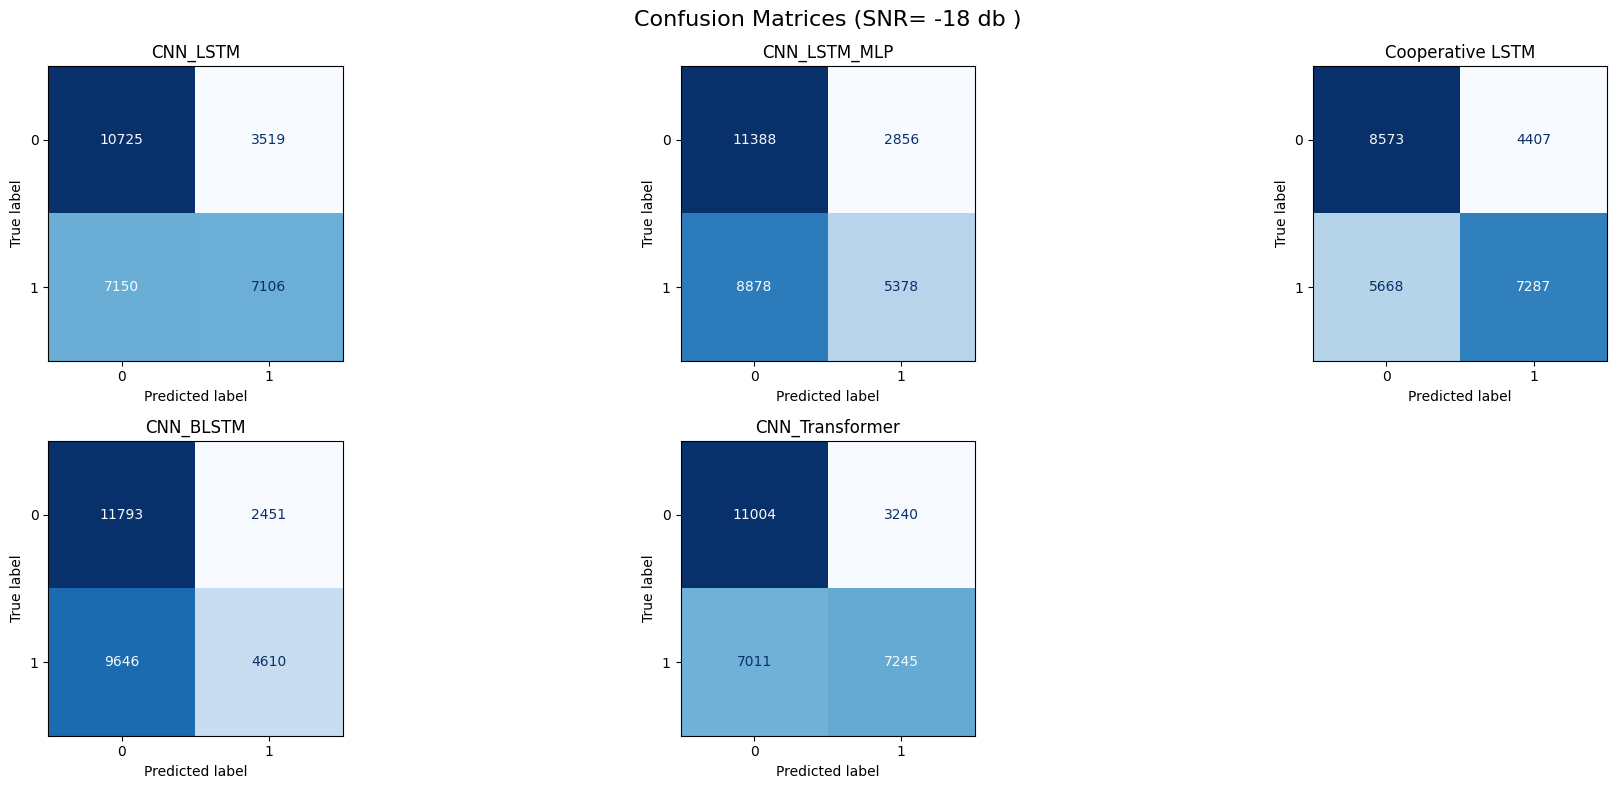

In [19]:
from matplotlib import cm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# ==============================
# Settings
# ==============================
snr_value = 18
threshold = 0.5

# ==============================
# Load Test Data
# ==============================
X_test = Xc[f'Xc{snr_value}_testX']

S = 4
idx = np.arange(S+1) * int(X_test.shape[0] / S)

Xu = X_test[idx[0]:idx[1]]
Xx = X_test[idx[1]:idx[2]]
Xy = X_test[idx[2]:idx[3]]
Xz = X_test[idx[3]:idx[4]]

Y_slice = Yc_test[idx[0]:idx[4]]

# ==============================
# Predictions for each model
# ==============================
y_CLSTM = CLSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_LSTM  = LSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_Cnn_blstm = Cnn_blstm.predict([Xu, Xx, Xy, Xz], verbose=0)

# Concatenate inputs for CNN_Transformer model which expects a single input
X_transformer_input = np.concatenate([Xu, Xx, Xy, Xz], axis=-1)
y_transformer_model = CNN_Transformer.predict(X_transformer_input, verbose=0)


# Cooperative model (separate input)
X_testP = Xcp[f'Xc{snr_value}_testP']
Sp = 3
pidx = np.arange(Sp+1) * int(X_testP.shape[0] / Sp)

XxP = X_testP[pidx[0]:pidx[1]]
XyP = X_testP[pidx[1]:pidx[2]]
XzP = X_testP[pidx[2]:pidx[3]]

Y_sliceP = Yc_testP[pidx[0]:pidx[3]]

y_Coop = Coop_model.predict([XxP, XyP, XzP], verbose=0)

# ==============================
# Convert to class labels

y_true  = Y_slice[:,1].astype(int)
y_trueP = Y_sliceP[:,1].astype(int)

y_pred_CLSTM = (y_CLSTM[:,1] >= threshold).astype(int)
y_pred_LSTM  = (y_LSTM[:,1] >= threshold).astype(int)
y_pred_Coop  = (y_Coop[:,1] >= threshold).astype(int)
y_pred_Cnn_blstm = (y_Cnn_blstm[:,1] >= threshold).astype(int)
y_pred_transformer = (y_transformer_model[:,1] >= threshold).astype(int)


# ==============================
# Confusion Matrices
# ==============================
cm_CLSTM = confusion_matrix(y_true, y_pred_CLSTM)
cm_LSTM  = confusion_matrix(y_true, y_pred_LSTM)
cm_Coop  = confusion_matrix(y_trueP, y_pred_Coop)
cm_Cnn_blstm = confusion_matrix(y_true, y_pred_Cnn_blstm)
cm_transformer = confusion_matrix(y_true, y_pred_transformer)

# ==============================
# Plot All Together
# ==============================
fig, axes = plt.subplots(2, 3, figsize=(20,8))

# CNN-LSTM
ConfusionMatrixDisplay(cm_CLSTM).plot(ax=axes[0, 0], cmap='Blues', colorbar=False)
axes[0, 0].set_title("CNN_LSTM")

# CNN-LSTM-MLP
ConfusionMatrixDisplay(cm_LSTM).plot(ax=axes[0, 1], cmap='Blues', colorbar=False)
axes[0, 1].set_title("CNN_LSTM_MLP")

# Cooperative LSTM
ConfusionMatrixDisplay(cm_Coop).plot(ax=axes[0, 2], cmap='Blues', colorbar=False)
axes[0, 2].set_title("Cooperative LSTM")

#cnn-BLSTM
ConfusionMatrixDisplay(cm_Cnn_blstm).plot(ax=axes[1, 0], cmap='Blues', colorbar=False)
axes[1, 0].set_title("CNN_BLSTM")

# CNN- Transformer
ConfusionMatrixDisplay(cm_transformer).plot(ax=axes[1, 1], cmap='Blues', colorbar=False)
axes[1, 1].set_title("CNN_Transformer")

# Remove the empty subplot at (1,2)
fig.delaxes(axes[1, 2])

plt.suptitle(f"Confusion Matrices (SNR= -18 db )", fontsize=16)
plt.tight_layout()
plt.show()

891/891 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 35s 39ms/step
811/811 ━━━━━━━━━━━━━━━━━━━━ 34s 42ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step
891/891 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step


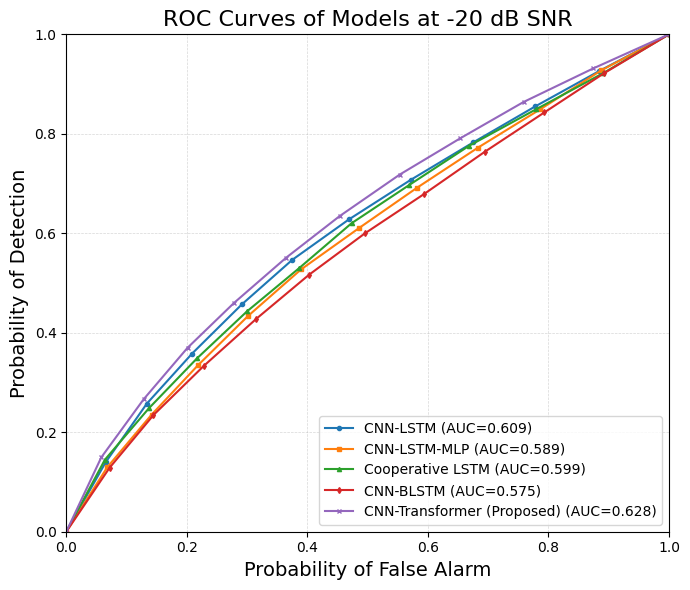

In [20]:
# ==============================
# Evaluate for SNR = -20 dB
# ==============================

snr_value = 20      # Xc20 corresponds to -20 dB

Xc20_test = Xc[f'Xc{snr_value}_testX']
Xc20_testP = Xcp[f'Xc{snr_value}_testP']

S = 4
Sp = 3

# Split data for CNN/LSTM models
idx = np.arange(S+1) * int(Xc20_test.shape[0] / S)

Xu_test = Xc20_test[idx[0]:idx[1]]
Xx_test = Xc20_test[idx[1]:idx[2]]
Xy_test = Xc20_test[idx[2]:idx[3]]
Xz_test = Xc20_test[idx[3]:idx[4]]

# Slice corresponding labels
Y20_test = Yc_test[idx[0]:idx[4]]

# Split data for Cooperative model
pidx = np.arange(Sp+1) * int(Xc20_testP.shape[0] / Sp)

Xx_testP = Xc20_testP[pidx[0]:pidx[1]]
Xy_testP = Xc20_testP[pidx[1]:pidx[2]]
Xz_testP = Xc20_testP[pidx[2]:pidx[3]]

# Slice cooperative labels
Y20_testP = Yc_testP[pidx[0]:pidx[3]]

# ==============================
# Predictions
# ==============================
y_CLSTM = CLSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_LSTM = LSTM_model.predict([Xu_test, Xx_test, Xy_test, Xz_test])
y_Coop = Coop_model.predict([Xx_testP, Xy_testP, Xz_testP])
y_Cnn_blstm = Cnn_blstm.predict([Xu_test, Xx_test, Xy_test, Xz_test])

X_transformer_input = np.concatenate([Xu_test, Xx_test, Xy_test, Xz_test], axis=-1)
y_CNN_Transformer_model = CNN_Transformer.predict(X_transformer_input)

# ==============================
# ROC Calculation
# ==============================
fp, tp, _ = roc_curve(Y20_test[:,1], y_CLSTM[:,1])
fp1, tp1, _ = roc_curve(Y20_test[:,1], y_LSTM[:,1])
fp3, tp3, _ = roc_curve(Y20_testP[:,1], y_Coop[:,1])
fp4, tp4, _ = roc_curve(Y20_test[:,1], y_Cnn_blstm[:,1])
fp5, tp5, _ = roc_curve(Y20_test[:,1], y_CNN_Transformer_model[:,1])

roc_auc = auc(fp, tp)
roc_auc1 = auc(fp1, tp1)
roc_auc3 = auc(fp3, tp3)
roc_auc4 = auc(fp4, tp4)
roc_auc5 = auc(fp5, tp5)

import numpy as np
import matplotlib.pyplot as plt

# Number of points to display on each ROC curve
n_points = 12

plt.figure(figsize=(7, 6))

# -------- CNN-LSTM --------
idx = np.linspace(0, len(fp)-1, n_points).astype(int)
plt.plot(fp[idx], tp[idx],
         '-o', markersize=3,
         label=f'CNN-LSTM (AUC={roc_auc:.3f})')

# -------- CNN-LSTM-MLP --------
idx = np.linspace(0, len(fp1)-1, n_points).astype(int)
plt.plot(fp1[idx], tp1[idx],
         '-s', markersize=3,
         label=f'CNN-LSTM-MLP (AUC={roc_auc1:.3f})')

# -------- Cooperative LSTM --------
idx = np.linspace(0, len(fp3)-1, n_points).astype(int)
plt.plot(fp3[idx], tp3[idx],
         '-^', markersize=3,
         label=f'Cooperative LSTM (AUC={roc_auc3:.3f})')

# -------- CNN-BLSTM --------
idx = np.linspace(0, len(fp4)-1, n_points).astype(int)
plt.plot(fp4[idx], tp4[idx],
         '-d', markersize=3,
         label=f'CNN-BLSTM (AUC={roc_auc4:.3f})')

# -------- CNN-Transformer --------
idx = np.linspace(0, len(fp5)-1, n_points).astype(int)
plt.plot(fp5[idx], tp5[idx],
         '-x', markersize=3,
         label=f'CNN-Transformer (Proposed) (AUC={roc_auc5:.3f})')

# Figure settings
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel('Probability of False Alarm', fontsize=14)
plt.ylabel('Probability of Detection', fontsize=14)
plt.title('ROC Curves of Models at -20 dB SNR', fontsize=16)

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

plt.legend(loc='lower right', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

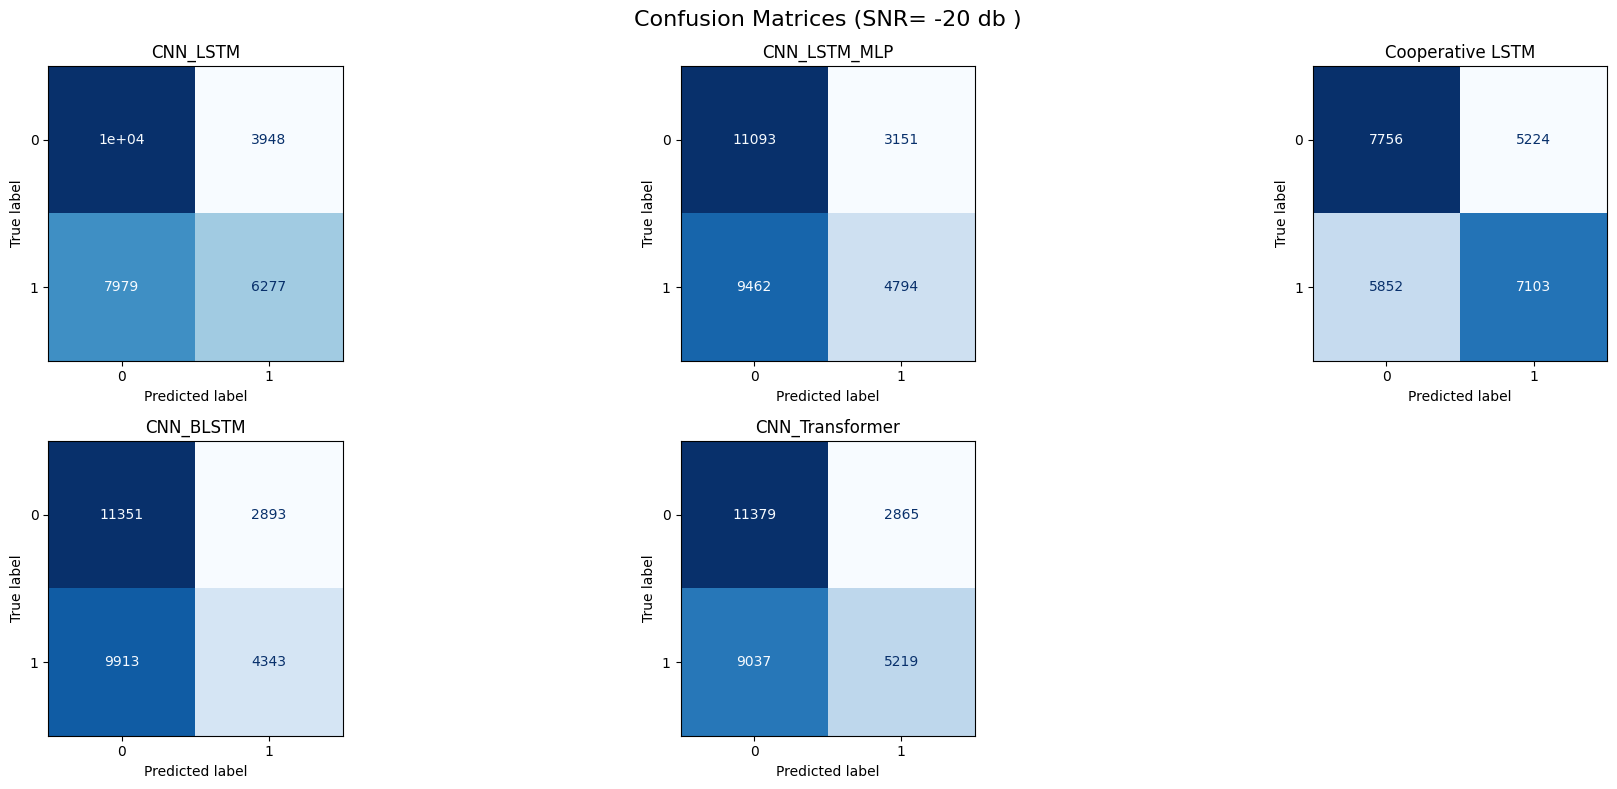

In [ ]:
from matplotlib import cm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# ==============================
# Settings
# ==============================
snr_value = 20
threshold = 0.5

# ==============================
# Load Test Data
# ==============================
X_test = Xc[f'Xc{snr_value}_testX']

S = 4
idx = np.arange(S+1) * int(X_test.shape[0] / S)

Xu = X_test[idx[0]:idx[1]]
Xx = X_test[idx[1]:idx[2]]
Xy = X_test[idx[2]:idx[3]]
Xz = X_test[idx[3]:idx[4]]

Y_slice = Yc_test[idx[0]:idx[4]]

# ==============================
# Predictions for each model
# ==============================
y_CLSTM = CLSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_LSTM  = LSTM_model.predict([Xu, Xx, Xy, Xz], verbose=0)
y_Cnn_blstm = Cnn_blstm.predict([Xu, Xx, Xy, Xz], verbose=0)

# Concatenate inputs for CNN_Transformer model which expects a single input
X_transformer_input = np.concatenate([Xu, Xx, Xy, Xz], axis=-1)
y_transformer_model = CNN_Transformer.predict(X_transformer_input, verbose=0)


# Cooperative model (separate input)
X_testP = Xcp[f'Xc{snr_value}_testP']
Sp = 3
pidx = np.arange(Sp+1) * int(X_testP.shape[0] / Sp)

XxP = X_testP[pidx[0]:pidx[1]]
XyP = X_testP[pidx[1]:pidx[2]]
XzP = X_testP[pidx[2]:pidx[3]]

Y_sliceP = Yc_testP[pidx[0]:pidx[3]]

y_Coop = Coop_model.predict([XxP, XyP, XzP], verbose=0)

# ==============================
# Convert to class labels

y_true  = Y_slice[:,1].astype(int)
y_trueP = Y_sliceP[:,1].astype(int)

y_pred_CLSTM = (y_CLSTM[:,1] >= threshold).astype(int)
y_pred_LSTM  = (y_LSTM[:,1] >= threshold).astype(int)
y_pred_Coop  = (y_Coop[:,1] >= threshold).astype(int)
y_pred_Cnn_blstm = (y_Cnn_blstm[:,1] >= threshold).astype(int)
y_pred_transformer = (y_transformer_model[:,1] >= threshold).astype(int)


# ==============================
# Confusion Matrices
# ==============================
cm_CLSTM = confusion_matrix(y_true, y_pred_CLSTM)
cm_LSTM  = confusion_matrix(y_true, y_pred_LSTM)
cm_Coop  = confusion_matrix(y_trueP, y_pred_Coop)
cm_Cnn_blstm = confusion_matrix(y_true, y_pred_Cnn_blstm)
cm_transformer = confusion_matrix(y_true, y_pred_transformer)

# ==============================
# Plot All Together
# ==============================
fig, axes = plt.subplots(2, 3, figsize=(20,8))

# CNN-LSTM
ConfusionMatrixDisplay(cm_CLSTM).plot(ax=axes[0, 0], cmap='Blues', colorbar=False)
axes[0, 0].set_title("CNN_LSTM")

# CNN-LSTM-MLP
ConfusionMatrixDisplay(cm_LSTM).plot(ax=axes[0, 1], cmap='Blues', colorbar=False)
axes[0, 1].set_title("CNN_LSTM_MLP")

# Cooperative LSTM
ConfusionMatrixDisplay(cm_Coop).plot(ax=axes[0, 2], cmap='Blues', colorbar=False)
axes[0, 2].set_title("Cooperative LSTM")

#cnn-BLSTM
ConfusionMatrixDisplay(cm_Cnn_blstm).plot(ax=axes[1, 0], cmap='Blues', colorbar=False)
axes[1, 0].set_title("CNN_BLSTM")

# CNN- Transformer
ConfusionMatrixDisplay(cm_transformer).plot(ax=axes[1, 1], cmap='Blues', colorbar=False)
axes[1, 1].set_title("CNN_Transformer")

# Remove the empty subplot at (1,2)
fig.delaxes(axes[1, 2])

plt.suptitle(f"Confusion Matrices (SNR= -20 db )", fontsize=16)
plt.tight_layout()
plt.show()

In [21]:
import time
import pandas as pd

# ==========================================
# Warm-up (Ignore first inference)
# ==========================================
CLSTM_model.predict([Xu_test[:10], Xx_test[:10], Xy_test[:10], Xz_test[:10]], verbose=0)
LSTM_model.predict([Xu_test[:10], Xx_test[:10], Xy_test[:10], Xz_test[:10]], verbose=0)
Coop_model.predict([Xx_testP[:10], Xy_testP[:10], Xz_testP[:10]], verbose=0)
Cnn_blstm.predict([Xu_test[:10], Xx_test[:10], Xy_test[:10], Xz_test[:10]], verbose=0)
CNN_Transformer.predict(X_transformer_input[:10], verbose=0)

# ==========================================
# Timing Function
# ==========================================
def measure_time(model, inputs, n_samples):

    start = time.perf_counter()

    model.predict(inputs, verbose=0)

    end = time.perf_counter()

    total_time = end - start
    avg_time = total_time / n_samples

    return total_time, avg_time


# ==========================================
# Measure inference time
# ==========================================

t1, avg1 = measure_time(
    CLSTM_model,
    [Xu_test, Xx_test, Xy_test, Xz_test],
    len(Xu_test)
)

t2, avg2 = measure_time(
    LSTM_model,
    [Xu_test, Xx_test, Xy_test, Xz_test],
    len(Xu_test)
)

t3, avg3 = measure_time(
    Coop_model,
    [Xx_testP, Xy_testP, Xz_testP],
    len(Xx_testP)
)

t4, avg4 = measure_time(
    Cnn_blstm,
    [Xu_test, Xx_test, Xy_test, Xz_test],
    len(Xu_test)
)

t5, avg5 = measure_time(
    CNN_Transformer,
    X_transformer_input,
    len(X_transformer_input)
)

# ==========================================
# Create Result Table
# ==========================================

results = pd.DataFrame({

    "Model":[
        "CNN-LSTM",
        "CNN-LSTM-MLP",
        "Cooperative LSTM",
        "CNN-BLSTM",
        "CNN-Transformer (Proposed)"
    ],

    "Total Time (s)":[
        t1,
        t2,
        t3,
        t4,
        t5
    ],

    "Sensing Time (ms/sample)":[
        avg1*1000,
        avg2*1000,
        avg3*1000,
        avg4*1000,
        avg5*1000
    ]

})

results["Total Time (s)"] = results["Total Time (s)"].round(4)
results["Sensing Time (ms/sample)"] = results["Sensing Time (ms/sample)"].round(4)

print(results)

                        Model  Total Time (s)  Sensing Time (ms/sample)
0                    CNN-LSTM         30.5068                    1.0704
1                CNN-LSTM-MLP         33.1238                    1.1622
2            Cooperative LSTM         41.1021                    1.5848
3                   CNN-BLSTM         29.2699                    1.0270
4  CNN-Transformer (Proposed)         29.7985                    1.0456


In [ ]:
import time
import numpy as np

def average_inference_time(model, inputs, n_samples, runs=10):
    # Warm-up
    model.predict(inputs, verbose=0)

    times = []
    for _ in range(runs):
        start = time.perf_counter()
        model.predict(inputs, verbose=0)
        end = time.perf_counter()
        times.append(end - start)

    avg_total = np.mean(times)
    avg_per_sample = avg_total / n_samples
    return avg_total, avg_per_sample

avg_total, avg_per_sample = average_inference_time(
    CNN_Transformer,
    X_transformer_input,
    len(X_transformer_input),
    runs=10
)

print(f"Average Total Inference Time : {avg_total:.4f} s")
print(f"Average Sensing Time         : {avg_per_sample*1000:.4f} ms/sample")

Average Total Inference Time : 3.3095 s
Average Sensing Time         : 0.1161 ms/sample
